# BAAC road accidents: Île-de-France, one full pass per year

Every step below runs **once per year in `YEARS`**. Each year is downloaded from its own
files (`Caract_YYYY.csv`, `Lieux_YYYY.csv`, ...) and checked: `BAACDataset.from_data_gouv`
raises an error if a table does not actually contain accidents of the requested year.

Needs `baac.py`, `commune_analysis.py` and `commune_rankings.py` in the same folder.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
from IPython.display import display

from baac import BAACDataset, DataGouvLoader, TABLE_KEYS
from commune_analysis import build_idf_dataset, CommuneAggregator, fetch_idf_communes
from commune_rankings import CommuneRanker

logging.basicConfig(level=logging.WARNING, format="%(levelname)s: %(message)s")

# ---- configuration: change here only ----
YEARS = [2025, 2024, 2023, 2022]    # one pass of the whole notebook per year
MIN_ACCIDENTS = 30                  # communes below this are not ranked
TOP_N = 10
OUT_DIR = Path("data")              # tables, figures, csv
CACHE_DIR = Path("cache")           # raw CSVs: downloaded once, reused on later runs

OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load every year

Prints the files really used for each year, then the number of rows per table.

In [2]:
loader = DataGouvLoader(cache_dir=CACHE_DIR)

national = {}                       # {year: BAACDataset for the whole country}
for year in YEARS:
    national[year] = BAACDataset.from_data_gouv(year, loader=loader)   # raises if not really `year`
    print(year, national[year].sources)

rows = pd.DataFrame({y: ds.summary()["rows"] for y, ds in national.items()}).T.astype("Int64")
rows.index.name = "year"
display(rows)

2025 {'vehicules': 'Vehicules_2025.csv', 'usagers': 'Usagers_2025.csv', 'lieux': 'Lieux_2025.csv', 'caract': 'Caract_2025.csv', 'immat': 'vehicules-immatricule-baac-2025.csv'}


2024 {'usagers': 'Usagers_2024.csv', 'lieux': 'Lieux_2024.csv', 'caract': 'Caract_2024.csv', 'immat': 'vehicules-immatricule-baac-2024.csv', 'vehicules': 'Vehicules_2024.csv'}


2023 {'lieux': 'lieux-2023.csv', 'vehicules': 'vehicules-2023.csv', 'usagers': 'usagers-2023.csv', 'caract': 'caract-2023.csv', 'immat': 'vehicules-immatricules-baac-2023.csv'}


2022 {'caract': 'carcteristiques-2022.csv', 'lieux': 'lieux-2022.csv', 'vehicules': 'vehicules-2022.csv', 'usagers': 'usagers-2022.csv', 'immat': 'vehicules-immatricules-baac-2022.csv'}


,caract,immat,lieux,usagers,vehicules
year,,,,,
2025,55093,93865,71116,126376,93865
2024,54402,<NA>,70248,125187,92678
2023,54822,<NA>,70860,125789,93585
2022,55302,<NA>,55302,126662,94493


## 2. Do all years have the same columns?

Differences between a year and the latest year (empty table = identical schemas).

In [3]:
latest = max(YEARS)
diffs = []
for year, ds in national.items():
    for key in TABLE_KEYS:
        here, there = key in ds.table_keys, key in national[latest].table_keys
        if here != there:
            diffs.append({"year": year, "table": key,
                          "only_in_year": "(whole table)" if here else "",
                          "only_in_latest": "(whole table)" if there else ""})
        elif here:
            a, b = set(ds.table(key).columns), set(national[latest].table(key).columns)
            if a != b:
                diffs.append({"year": year, "table": key,
                              "only_in_year": sorted(a - b), "only_in_latest": sorted(b - a)})

if diffs:
    display(pd.DataFrame(diffs))
else:
    print(f"Same tables and columns in every year ({min(YEARS)}-{max(YEARS)}).")

,year,table,only_in_year,only_in_latest
0,2024,immat,,(whole table)
1,2023,immat,,(whole table)
2,2022,immat,,(whole table)


## 3. Schema figure for each year

Saved as `data/baac_<year>_schemas.png`; only the latest year is displayed.

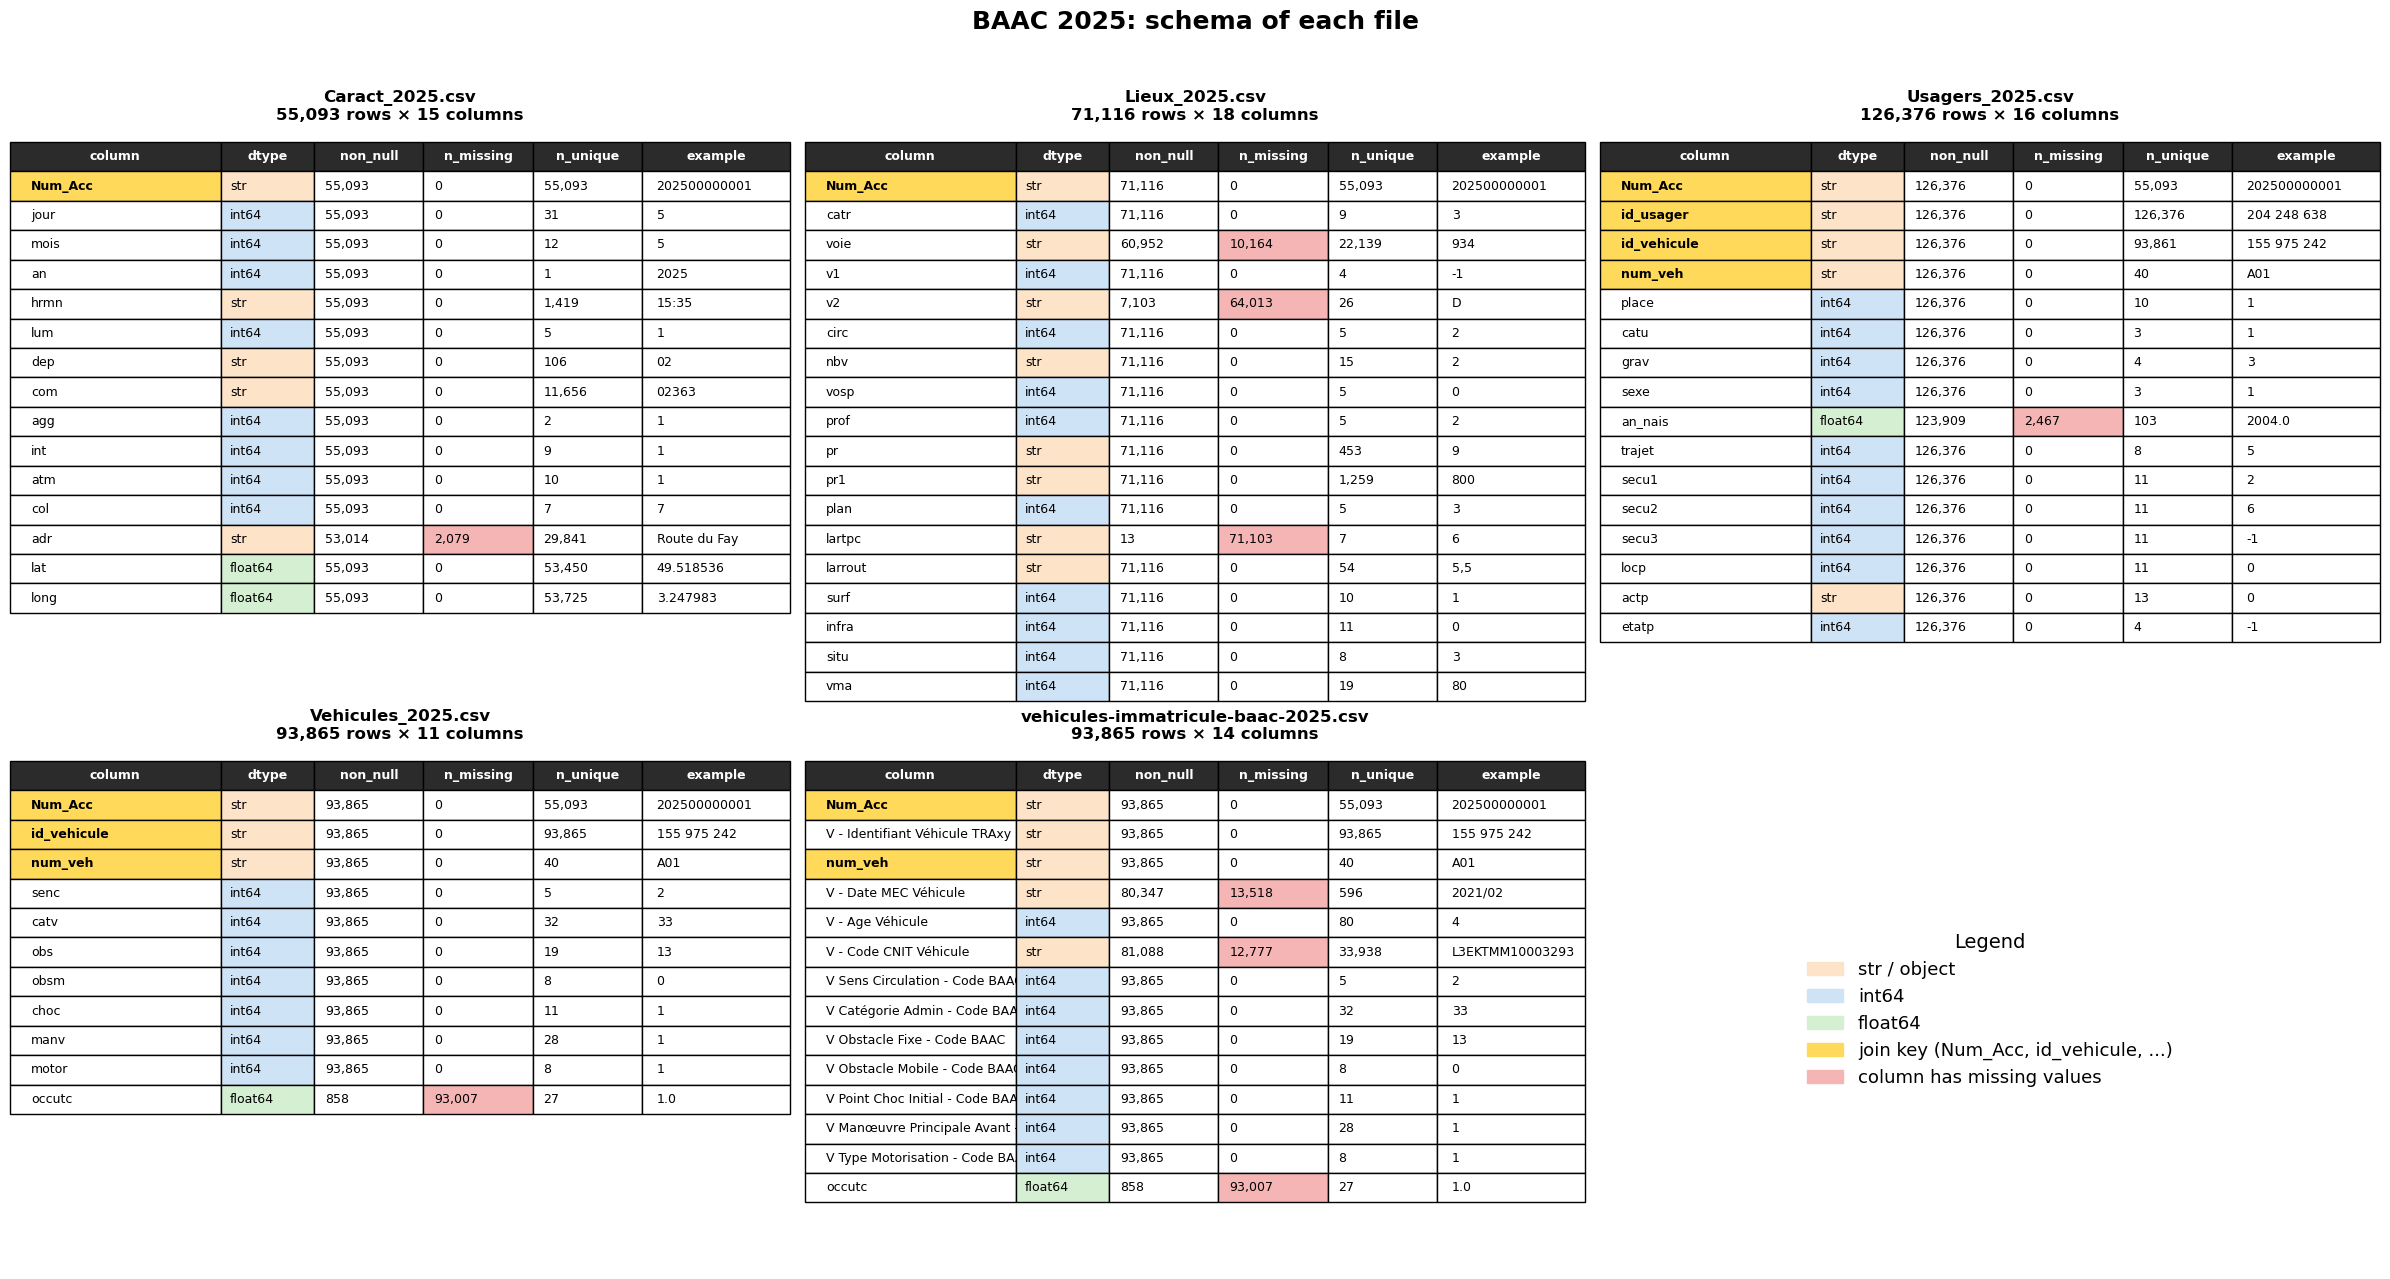

In [4]:
DTYPE_COLORS = {"str": "#fde4c8", "object": "#fde4c8", "int64": "#cfe3f7", "float64": "#d4efd2"}
KEY_COLOR, MISSING_COLOR = "#ffd95a", "#f5b5b5"
JOIN_KEYS = {"Num_Acc", "id_vehicule", "id_usager", "num_veh"}
HEADERS = ["column", "dtype", "non_null", "n_missing", "n_unique", "example"]


def describe_columns(df):
    return pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "non_null": df.notna().sum().values,
        "n_missing": df.isna().sum().values,
        "n_unique": df.nunique().values,
        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })


def plot_schemas(ds, year):
    keys = [k for k in TABLE_KEYS if k in ds.table_keys]
    fig, axes = plt.subplots(2, 3, figsize=(24, 13))
    axes = axes.flatten()

    for ax, key in zip(axes, keys):
        df = ds.table(key)
        schema = describe_columns(df)
        ax.axis("off")
        ax.set_title(f"{ds.sources.get(key, key)}\n{len(df):,} rows × {len(schema)} columns",
                     fontsize=12, fontweight="bold", pad=8)

        cell_text = [[str(r.column), r.dtype, f"{r.non_null:,}", f"{r.n_missing:,}",
                      f"{r.n_unique:,}", str(r.example)[:18]] for r in schema.itertuples()]
        tbl = ax.table(cellText=cell_text, colLabels=HEADERS, loc="upper center", cellLoc="left",
                       colWidths=[0.27, 0.12, 0.14, 0.14, 0.14, 0.19])
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1, 1.55)

        for j in range(len(HEADERS)):
            tbl[0, j].set_facecolor("#2b2b2b")
            tbl[0, j].set_text_props(color="white", fontweight="bold")
        for i, r in enumerate(schema.itertuples(), start=1):
            tbl[i, 1].set_facecolor(DTYPE_COLORS.get(r.dtype, "#eeeeee"))
            if r.column in JOIN_KEYS:
                tbl[i, 0].set_facecolor(KEY_COLOR)
                tbl[i, 0].set_text_props(fontweight="bold")
            if r.n_missing > 0:
                tbl[i, 3].set_facecolor(MISSING_COLOR)

    for ax in axes[len(keys):]:
        ax.axis("off")
    axes[-1].legend(handles=[
        mpatches.Patch(color="#fde4c8", label="str / object"),
        mpatches.Patch(color="#cfe3f7", label="int64"),
        mpatches.Patch(color="#d4efd2", label="float64"),
        mpatches.Patch(color=KEY_COLOR, label="join key (Num_Acc, id_vehicule, ...)"),
        mpatches.Patch(color=MISSING_COLOR, label="column has missing values"),
    ], loc="center", fontsize=13, title="Legend", title_fontsize=14, frameon=False)

    fig.suptitle(f"BAAC {year}: schema of each file", fontsize=18, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    return fig


for year, ds in national.items():
    fig = plot_schemas(ds, year)
    fig.savefig(OUT_DIR / f"baac_{year}_schemas.png", dpi=200, bbox_inches="tight")
    if year == max(YEARS):
        plt.show()
    plt.close(fig)

## 4. Île-de-France pipeline for each year

For every year: keep the 8 Île-de-France departments, aggregate by commune (communes with
0 accidents included, using the official commune list), run the integrity checks, rank, and save
`data/top<N>_severity_<year>` and `data/top<N>_vulnerability_<year>` (`.png` and `.csv`).

In [5]:
ref = fetch_idf_communes()          # official list of IDF communes (the same for every year)
if ref is None:
    print("Official commune list unavailable: communes with 0 accidents will not be listed.")

by_year, summary = {}, []
for year, ds in national.items():
    idf = build_idf_dataset(ds)
    by = CommuneAggregator(idf, reference_communes=ref).by_commune()

    # integrity checks, per year
    assert by["accidents"].sum() == len(idf.caract), f"{year}: accidents lost in the aggregation"
    assert by.index.is_unique, f"{year}: duplicated commune codes"

    CommuneRanker(by, year=year, min_accidents=MIN_ACCIDENTS, top_n=TOP_N).save(OUT_DIR)

    by_year[year] = by
    summary.append({
        "year": year,
        "accidents_france": len(ds.caract),
        "accidents_idf": len(idf.caract),
        "communes_with_accidents": int((by["accidents"] > 0).sum()),
        "communes_with_0": int((by["accidents"] == 0).sum()),
        "communes_ranked": int((by["accidents"] >= MIN_ACCIDENTS).sum()),
        "codes_not_in_reference": int((~by["in_reference"]).sum()) if "in_reference" in by else None,
    })
    print(f"{year}: done")

2025: done
2024: done
2023: done
2022: done


In [6]:
summary = pd.DataFrame(summary).set_index("year")
display(summary)

,accidents_france,accidents_idf,communes_with_accidents,communes_with_0,communes_ranked,codes_not_in_reference
year,,,,,,
2025,55093,14760,743,543,129,21
2024,54402,15366,751,536,129,21
2023,54822,15943,736,550,126,21
2022,55302,16358,728,558,127,21


**Reading the summary**

- Different numbers in every row confirm that each year comes from its own files (identical rows would be a red flag).
- `codes_not_in_reference`: commune codes present in the accident data but not in the *current* official list
  (Paris coded `75`, communes merged since, typos). These accidents are still counted.
- `communes_ranked`: how many communes pass the `MIN_ACCIDENTS` threshold and can appear in a top 10.

In [7]:
year = max(YEARS)
by_year[year].head(15)

,dep,accidents,vehicles,users,killed,hospitalised,light_injury,unharmed,pedestrians,cyclists,edv_users,vulnerable_accidents,in_reference,severe_per_100_accidents,pct_vulnerable_accidents
com,,,,,,,,,,,,,,,
75116,75,424,783,958,8,41,444,465,74,90,20,158,False,11.6,37.3
75119,75,264,468,581,2,24,277,278,59,62,37,131,False,9.8,49.6
93066,93,256,488,595,1,30,272,292,39,18,23,74,True,12.1,28.9
75112,75,252,477,596,5,19,279,293,43,56,21,95,False,9.5,37.7
75117,75,241,408,524,1,19,261,243,57,43,25,109,False,8.3,45.2
75118,75,233,412,536,3,18,249,266,68,45,26,119,False,9.0,51.1
75113,75,232,416,518,0,18,247,253,50,49,20,108,False,7.8,46.6
92036,92,224,438,553,1,18,257,277,27,16,16,54,True,8.5,24.1
75115,75,224,375,492,3,17,245,227,61,75,17,131,False,8.9,58.5


## 5. All years in one table

One row per (year, commune), saved for trend analysis.

In [8]:
all_years = pd.concat(by_year, names=["year", "com"])
path = OUT_DIR / f"by_commune_{min(YEARS)}-{max(YEARS)}.csv"
all_years.to_csv(path)
print(f"{len(all_years):,} rows saved to {path}")
all_years.head()

5,145 rows saved to data\by_commune_2022-2025.csv


dep  accidents  vehicles  users  killed  hospitalised  \
year com                                                           
2025 75116  75        424       783    958       8            41   
     75119  75        264       468    581       2            24   
     93066  93        256       488    595       1            30   
     75112  75        252       477    596       5            19   
     75117  75        241       408    524       1            19   

            light_injury  unharmed  pedestrians  cyclists  edv_users  \
year com                                                               
2025 75116           444       465           74        90         20   
     75119           277       278           59        62         37   
     93066           272       292           39        18         23   
     75112           279       293           43        56         21   
     75117           261       243           57        43         25   

            vulnerable_accidents  in_reference  severe_per_100_accidents  \
year com                                                                   
2025 75116                   158         False                      11.6   
     75119                   131         False                       9.8   
     93066                    74          True                      12.1   
     75112                    95         False                       9.5   
     75117                   109         False                       8.3   

            pct_vulnerable_accidents  
year com                              
2025 75116                      37.3  
     75119                      49.6  
     93066                      28.9  
     75112                      37.7  
     75117                      45.2

In [ ]:
from commune_stability import YearComparison

cmp = YearComparison(by_year[2022], by_year[2023], 2022, 2023,
                     min_accidents=30, top_n=10)
stability = cmp.report()

SEVERITY: 2022 vs 2023   [Killed + hospitalised people per 100 accidents]

1) Overlap of the top 10 (communes with >= 30 accidents only)
   eligible communes: 2022: 127 | 2023: 126 | both: 119
   in the top 10 BOTH years : 2/10  ['77373', '93055']
   only in 2022              : 8  ['77294', '78551', '91201', '91687', '93031', '93053', '93072', '95018']
   only in 2023              : 8  ['91223', '92023', '93008', '93014', '93029', '93051', '93059', '93063']
   overlap (Jaccard)         : 0.11
   expected by pure chance   : ~0.8 communes (if the two rankings were unrelated)
   2022 top 10 found within the top 20 of 2023: 3/10
   2023 top 10 found within the top 20 of 2022: 4/10

2) Do high-rate communes stay high? (all 119 communes eligible both years)
   rank correlation (Spearman)     : 0.36   (1 = same order, 0 = unrelated)
   typical year-to-year change     : median 3.0 | 90th percentile 9.4 points
   'drastic' threshold used        : >= 10 points AND |z| >= 1.96

3) Communes in the

In [10]:
from commune_stability import YearComparison

years = [2023, 2024, 2025]      # <- CHANGE HERE: the 3 years to compare, oldest first

stability = {}
for a, b in zip(years, years[1:]):
    print(f"\n{'#' * 100}\n{a} vs {b}\n{'#' * 100}")
    stability[(a, b)] = YearComparison(by_year[a], by_year[b], a, b,
                                       min_accidents=30, top_n=10).report()

# communes in the top 10 in all 3 years
first, second = stability[(years[0], years[1])], stability[(years[1], years[2])]
for rule in ("severity", "vulnerability"):
    tops = [first[rule]["stats"]["top_a"], first[rule]["stats"]["top_b"], second[rule]["stats"]["top_b"]]
    print(f"{rule}: top 10 in all 3 years -> {sorted(set.intersection(*tops))}")


####################################################################################################
2023 vs 2024
####################################################################################################
SEVERITY: 2023 vs 2024   [Killed + hospitalised people per 100 accidents]

1) Overlap of the top 10 (communes with >= 30 accidents only)
   eligible communes: 2023: 126 | 2024: 129 | both: 119
   in the top 10 BOTH years : 1/10  ['77373']
   only in 2023              : 9  ['91223', '92023', '93008', '93014', '93029', '93051', '93055', '93059', '93063']
   only in 2024              : 9  ['77186', '77284', '77288', '78551', '93031', '94044', '94071', '94079', '95018']
   overlap (Jaccard)         : 0.05
   expected by pure chance   : ~0.8 communes (if the two rankings were unrelated)
   2023 top 10 found within the top 20 of 2024: 2/10
   2024 top 10 found within the top 20 of 2023: 3/10

2) Do high-rate communes stay high? (all 119 communes eligible both years)
   rank corre

In [11]:
from commune_stability import YearComparison
from commune_rankings import SEVERITY, VULNERABILITY

N = 10
yc = YearComparison(by_year[years[0]], by_year[years[1]], years[0], years[1],
                    min_accidents=30, top_n=N)       # only used for its ranking() method

def top(year, rule):
    r = yc.ranking(by_year[year], rule)
    return set(r[r <= N].index)

sev = {y: top(y, SEVERITY) for y in years}
vul = {y: top(y, VULNERABILITY) for y in years}

# 1) per year: severe communes that are also in the vulnerable top
for y in years:
    both = sev[y] & vul[y]
    print(f"{y}: {len(both)}/{N} severe communes are also in the vulnerable top {N} -> {sorted(both)}")

# 2) same question for the communes that are recurrent (in the top in all years)
stable_sev = set.intersection(*sev.values())
stable_vul = set.intersection(*vul.values())
print(f"\nRecurrent severe (all {len(years)} years)    : {sorted(stable_sev)}")
print(f"Recurrent vulnerable (all {len(years)} years): {sorted(stable_vul)}")
print(f"In both recurrent lists                : {sorted(stable_sev & stable_vul)}")

2023: 0/10 severe communes are also in the vulnerable top 10 -> []
2024: 0/10 severe communes are also in the vulnerable top 10 -> []
2025: 1/10 severe communes are also in the vulnerable top 10 -> ['75107']

Recurrent severe (all 3 years)    : []
Recurrent vulnerable (all 3 years): ['75101', '75102', '75103', '75104', '75106', '75109', '75110', '75111']
In both recurrent lists                : []
